In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,BatchNormalization,Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.drop_duplicates(inplace=True)

In [8]:
label = LabelEncoder()

df["encoded_gender"] = label.fit_transform(df["gender"])
var = dict(zip(df["gender"],df["encoded_gender"]))
print(var)


df["encoded_smoking"] = label.fit_transform(df["smoking_history"])
var1 = dict(zip(df["smoking_history"],df["encoded_smoking"]))
print(var1)

{'Female': 0, 'Male': 1, 'Other': 2}
{'never': 4, 'No Info': 0, 'current': 1, 'former': 3, 'ever': 2, 'not current': 5}


In [9]:
df.drop(columns=["smoking_history", "gender"],inplace=True)

In [10]:
df.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,encoded_gender,encoded_smoking
0,80.0,0,1,25.19,6.6,140,0,0,4
1,54.0,0,0,27.32,6.6,80,0,0,0
2,28.0,0,0,27.32,5.7,158,0,1,4
3,36.0,0,0,23.45,5.0,155,0,0,1
4,76.0,1,1,20.14,4.8,155,0,1,1


In [11]:
#feature selection:
x = df.drop(columns=["diabetes"])
y = df["diabetes"]

In [12]:
#data splitting:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [13]:
#scaling :
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [21]:
# ann architecture:
model = Sequential()

#input layer:
model.add(Dense(512,activation="sigmoid",input_dim=8))

#hidden layer:
model.add(Dense(256,activation="relu"))

model.add(Dense(128,activation="relu"))

model.add(Dense(64,activation="relu"))

#output layer:
model.add(Dense(1,activation="sigmoid"))

model.summary()

c:\Users\Anushkha Bhagra\Downloads\deep learning\ANN\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 512)            │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,153 (692.00 KB)

 Trainable params: 177,153 (692.00 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
#model compile:
model.compile(optimizer="adam",loss= "binary_crossentropy", metrics= ["accuracy"])

In [33]:
#applying early stopping:
early = EarlyStopping(monitor="val_loss",
                      patience= 5,
                     restore_best_weights=True)

In [34]:
history = model.fit(x_train_scaled,y_train,batch_size= 32,epochs=10,validation_split=0.2,verbose=1)

Epoch 1/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9706 - loss: 0.0844 - val_accuracy: 0.9639 - val_loss: 0.0949
Epoch 2/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.9708 - loss: 0.0840 - val_accuracy: 0.9677 - val_loss: 0.0892
Epoch 3/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.9711 - loss: 0.0835 - val_accuracy: 0.9676 - val_loss: 0.0894
Epoch 4/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 43s 18ms/step - accuracy: 0.9710 - loss: 0.0834 - val_accuracy: 0.9679 - val_loss: 0.0877
Epoch 5/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 30s 15ms/step - accuracy: 0.9710 - loss: 0.0837 - val_accuracy: 0.9676 - val_loss: 0.0886
Epoch 6/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 23s 6ms/step - accuracy: 0.9706 - loss: 0.0845 - val_accuracy: 0.9678 - val_loss: 0.0880
Epoch 7/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9712 - loss: 0.0831 - val_accuracy: 0.9675 - val_loss: 0.0876
Epoch 8/10
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9706 - loss:

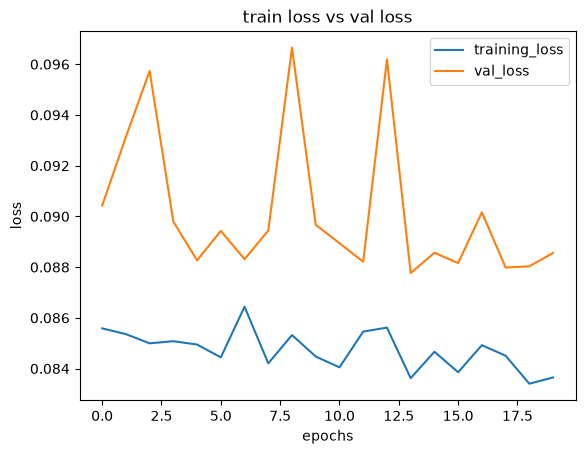

In [31]:
# graph:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label = "val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

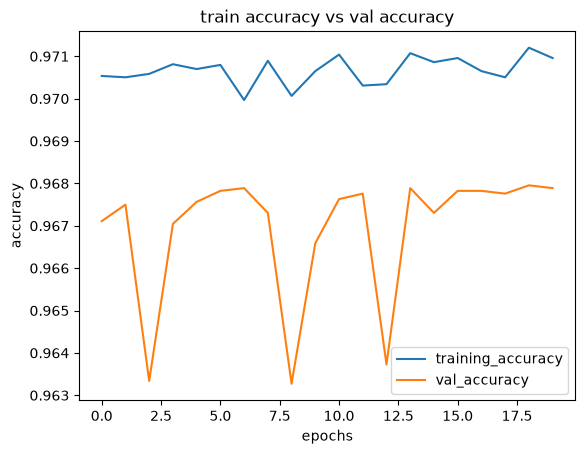

In [30]:
# graph:
plt.plot(history.history["accuracy"],label="training_accuracy")
plt.plot(history.history["val_accuracy"],label = "val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()